# 08H: Development scoring evaluation

Compare fixed peer-scoring methods and one lightweight peer-context ranker on the existing development screen. This is a development study, not an untouched test result.

## Saved-output evidence copy

This notebook records the completed run for repository review. Its code and markdown match the clean runnable notebook. Private scene visuals and identifier-bearing output were removed. Safe aggregate tables and charts were retained.

Run stage: `08H-screen100`  
Clean notebook SHA-256: `19f7f3e79779454ae58128fab0411c32870d1f8263a95acff058c62a22b923e7`  
Downloaded saved-output SHA-256: `56a58eeb090cedeb8d7a1f7fec178bed611f81832db02652df2b7ba8d4bc6bc5`


## Study boundary

        The original 2,000-scene split is unchanged. Use the existing 100-scene development screen, with all 20 views and two mask routes. The 20-scene smoke run is a fixed nested subset for runtime checks. It is not a new train/test split.

        Keep DINOv2-small, crop preparation, model revision and input masks identical across scoring methods. Supplied masks show scoring capability; existing LocateAnything and SAM masks show automatic-region performance. No detection or segmentation model is trained or rerun here.

        The main deployment-style comparison uses automatic masks, predicted identities and three views. Two and five views are secondary. Twenty-view reference-identity fusion is a capability diagnostic, not a web-app result. Protected calibration and internal-lock scenes are outside this study.

## Paths and run settings

Set each path to an attached, versioned resource. The code uses these exact paths and does not search the raw dataset. Keep the model-only and evaluator resources separate.

In [1]:
from pathlib import Path
import os
import sys
import subprocess
import json
import shutil
import stat
from hashlib import sha256
from pathlib import PurePosixPath
from zipfile import ZipFile

INPUT_ROOT = Path('/kaggle/input')
mount_roots = []
for pattern in ('*', 'datasets/*/*', 'datasets/*/*/versions/*', 'notebooks/*/*', 'notebooks/*/*/versions/*'):
    mount_roots.extend(path.resolve() for path in INPUT_ROOT.glob(pattern) if path.is_dir())
mount_roots = sorted(set(mount_roots))
source_mounts = [
    path for path in mount_roots
    if any(part.startswith('vpi-development-scoring-source') for part in path.parts[-4:])
]
source_markers = []
for source_mount in source_mounts:
    source_markers.extend(path for path in source_mount.rglob('comparison_base.json') if path.is_file())
source_candidates = [path.parent for path in sorted(set(source_markers)) if (path.parent / 'scripts/run_scoring_comparison.py').is_file()]
if not source_candidates:
    source_archives = []
    for source_mount in source_mounts:
        source_archives.extend(path for path in source_mount.rglob('scoring-comparison-source-*.zip') if path.is_file())
    source_archives = sorted(set(source_archives))
    if len(source_archives) != 1:
        mounts = [path.as_posix() for path in mount_roots]
        raise ValueError(
            'The attached source dataset does not contain a valid expanded source tree '
            f'or one source archive. Mounts: {mounts}'
        )
    archive = source_archives[0]
    extraction = Path('/kaggle/working/scoring-source')
    temporary = extraction.with_name(extraction.name + '.incomplete')
    if extraction.exists() or temporary.exists():
        raise FileExistsError('Source extraction destination is not empty')
    temporary.mkdir(parents=True)
    with ZipFile(archive) as handle:
        entries = handle.infolist()
        names = [entry.filename for entry in entries]
        if not entries or len(names) != len(set(names)) or handle.testzip() is not None:
            raise ValueError('Source archive is empty, duplicated or corrupt')
        for entry in entries:
            relative = PurePosixPath(entry.filename)
            mode = entry.external_attr >> 16
            if entry.is_dir() or relative.is_absolute() or any(part in ('', '.', '..') for part in relative.parts) or stat.S_ISLNK(mode):
                raise ValueError('Source archive contains an unsafe path')
            destination = temporary.joinpath(*relative.parts)
            destination.parent.mkdir(parents=True, exist_ok=True)
            with handle.open(entry) as source_stream, destination.open('xb') as target_stream:
                shutil.copyfileobj(source_stream, target_stream, length=1024 * 1024)
    temporary.replace(extraction)
    source_candidates = [extraction / 'scoring-comparison']
    Path('/kaggle/working/source_archive_receipt.json').write_text(json.dumps({'file': archive.name, 'sha256': sha256(archive.read_bytes()).hexdigest()}, sort_keys=True))
if len(source_candidates) != 1:
    raise ValueError(f'Expected one scoring source resource, found {len(source_candidates)}')
SOURCE = source_candidates[0]
sys.path.insert(0, str(SOURCE / 'scripts'))
from kaggle_mounts import find_recovery, materialize_sealed_resource
MODEL_INPUT = materialize_sealed_resource(
    INPUT_ROOT,
    kind='model-input',
    archive_name='scoring-comparison-model-input.zip',
    archive_sha256='6d6b45aa211ea595524729123870307ee5295ada48e6fd8f1898935f477b6901',
    destination=Path('/kaggle/working/scoring-model-resource'),
    expected_lock_sha256='9baa53454d2482caf8240e7a8b591a6e9e9646dd160c5b3abdc8bd17265ebda1',
)
OUTPUT = Path('/kaggle/working/scoring-comparison-08h')
PYTHON = Path(sys.executable)
PACKAGE_ROOT = Path('/kaggle/working/comparison-packages')
# Use smoke20 first. Change only this value to screen100 after the smoke evidence passes review.
COHORT = 'screen100'
# Set this to True only in a prepared continuation wrapper that attaches a sealed recovery archive.
EXPECT_RECOVERY = False
RECOVERY = find_recovery(INPUT_ROOT) if '08H' == '08G' else None
recovery_state = {
    'event': 'recovery_discovery',
    'expected': EXPECT_RECOVERY,
    'attached': RECOVERY is not None,
    'archive': RECOVERY[0].name if RECOVERY else None,
}
print(json.dumps(recovery_state, sort_keys=True))
if '08H' == '08G' and EXPECT_RECOVERY and RECOVERY is None:
    raise FileNotFoundError('This continuation run requires one sealed recovery archive and manifest')

{"archive": null, "attached": false, "event": "recovery_discovery", "expected": false}


## Runtime preparation

        Install the pinned study dependencies into a run-local package directory while retaining Kaggle's CUDA-compatible PyTorch. This avoids relying on `venv`, which is not available in every Kaggle container, and does not replace CUDA libraries. Package installation is bounded. Authentication, dependency and input errors must be fixed before inference; they are not reasons to retry a full GPU run.

In [2]:
if not (SOURCE / 'comparison_base.json').is_file():
    raise FileNotFoundError('Set SOURCE to the attached source package')
if not (MODEL_INPUT / 'artifact_lock.json').is_file():
    raise FileNotFoundError('Set MODEL_INPUT to the attached model-only package')
PACKAGE_ROOT.mkdir(parents=True, exist_ok=True)
subprocess.run([
    str(PYTHON), '-m', 'pip', 'install', '--disable-pip-version-check',
    '--retries', '1', '--timeout', '60', '--only-binary=:all:',
    '--upgrade', '--target', str(PACKAGE_ROOT),
    '-r', str(SOURCE / 'requirements/scoring-comparison.txt'),
], check=True, timeout=600)
os.environ['PYTHONPATH'] = os.pathsep.join([
    str(SOURCE / 'src'), str(PACKAGE_ROOT), os.environ.get('PYTHONPATH', '')
]).rstrip(os.pathsep)
sys.path.insert(0, str(PACKAGE_ROOT))
from scoring_comparison_runtime import run_bounded
OUTPUT.parent.mkdir(parents=True, exist_ok=True)
RUNNER = SOURCE / 'scripts/run_scoring_comparison.py'

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.2/91.2 kB 2.0 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.0/62.0 kB 4.5 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 kB 3.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 40.6/40.6 kB 2.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.4/57.4 kB 4.3 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 125.0/125.0 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.6/11.6 MB 80.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 780.8/780.8 kB 36.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 88.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 104.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.9/6.9 MB 100.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.2/35.2 MB 55.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.39.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
google-adk 1.29.0 requires google-cloud-bigquery-storage>=2.0.0, which is not installed.
datasets 5.0.0 requires fsspec[http]<=2026.4.0,>=2023.1.0, but you have fsspec 2026.7.0 which is incompatible.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.10.8 which is incompatible.
ydata-profiling 4.18.4 requires numpy<2.4,>=1.22, but you have numpy 2.5.1 which is incompatible.
google-colab 1.0.0 requires jupyter-server==2.14.0, but you have jupyter-server 2.12.5 which is incompatible.
google-colab 1.0.0 requires pandas==2.2.2, but you have pandas 2.3.3 which is incompatible.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
moviepy 1.0.3 requires decorator

## Input validation

Check membership, file hashes, image decoding, mask dimensions, enclosing boxes and unique candidate IDs before allocating a model. Labels and reference object IDs are not accepted by the prediction schema.

In [3]:
run_bounded([str(PYTHON), str(RUNNER), 'preflight', '--model-input', str(MODEL_INPUT), '--output', str(OUTPUT)], OUTPUT.parent / 'input-validation.log', idle_seconds=300, total_seconds=600)

{'scenes': 100, 'counts': {'supplied_views': 2000, 'supplied_objects': 7700, 'supplied_insufficient_views': 0, 'automatic_views': 2000, 'automatic_objects': 7594, 'automatic_insufficient_views': 59}, 'input_lock_sha256': '9baa53454d2482caf8240e7a8b591a6e9e9646dd160c5b3abdc8bd17265ebda1'}


## Local contracts

Run the scorer, notebook, integrity and timeout tests in the installed environment before continuing. A failed test stops the notebook before model loading.

In [4]:
test_env = dict(os.environ, PYTHONDONTWRITEBYTECODE='1', MPLCONFIGDIR='/kaggle/working/matplotlib')
subprocess.run([str(PYTHON), '-m', 'pytest', '-p', 'no:cacheprovider', str(SOURCE / 'tests/test_scoring_comparison.py'), str(SOURCE / 'tests/test_peer_support_and_context.py'), '-q'], check=True, env=test_env, cwd='/kaggle/working', timeout=300)

.........................................                                [100%]
41 passed in 8.20s


CompletedProcess(args=['/usr/bin/python3', '-m', 'pytest', '-p', 'no:cacheprovider', '/kaggle/input/datasets/esreekarreddy/vpi-development-scoring-source/scoring-comparison/tests/test_scoring_comparison.py', '/kaggle/input/datasets/esreekarreddy/vpi-development-scoring-source/scoring-comparison/tests/test_peer_support_and_context.py', '-q'], returncode=0)

## Locked predictions and evaluator data

Attach the exact prediction output from 08G and the matching development-only evaluator resource. This stage runs on CPU. Fixed methods are not tuned. The small peer-context ranker is trained only through asset-grouped cross-validation and produces out-of-fold scores for every reported development result.

In [5]:
from kaggle_mounts import find_prediction
import hashlib
model_lock_sha256 = hashlib.sha256((MODEL_INPUT / 'artifact_lock.json').read_bytes()).hexdigest()
PREDICTIONS = find_prediction(INPUT_ROOT, expected_input_lock_sha256=model_lock_sha256)
EVALUATOR = materialize_sealed_resource(
    INPUT_ROOT,
    kind='evaluator-only',
    archive_name='scoring-comparison-evaluator-only.zip',
    archive_sha256='86ac512005af5fdceb64c0fb666998832b8ee08ef96d1fccca23c6e35f420c12',
    destination=Path('/kaggle/working/scoring-evaluator-resource'),
    expected_lock_sha256='8012cd20c63b3788f861f2ba991b3181a0c1666f26e176beeee370228c8500c3',
)
if not (PREDICTIONS / 'prediction_lock.json').is_file():
    raise FileNotFoundError('Attach the verified 08G output')
if not (EVALUATOR / 'artifact_lock.json').is_file():
    raise FileNotFoundError('Attach the matching evaluator-only resource')

## Evaluation rules

        Report supplied masks with reference identity, automatic masks with reference identity, and automatic masks with predicted identity. The last route is closest to deployment. Reference identity is used only by the evaluator after predictions are locked.

        Missing detections and insufficient-peer views are not removed from the denominator. Average precision and recall use every positive object in the scene. An unmatched predicted track remains a false candidate. Mixed tracks receive identity credit only with a one-to-one, strict-majority reference match.

        Scores are fused by mean normalized rank across the views supporting a track. Single-view winners and track purity are reported because limited support can make fusion misleading. Exact ties use neutral IDs for deterministic order; expected, best and worst top-one tie results are also reported.

        The context ranker uses only relative component scores, silhouette deviations and peer distances. It cannot use scene names, categories, asset identifiers, object order or protected-role fields as predictive inputs. Every asset group stays within one fold. Each completed fold is checkpointed and can be reused after a reporting or tracking failure.

        Paired 95% intervals resample asset groups, not independent views. These development intervals are descriptive after prior experiments; they do not establish unseen-test generalization.

In [6]:
run_bounded([str(PYTHON), str(RUNNER), 'evaluate', '--model-input', str(MODEL_INPUT), '--predictions', str(PREDICTIONS), '--evaluator', str(EVALUATOR), '--output', str(OUTPUT)], OUTPUT.parent / 'evaluation.log', idle_seconds=900, total_seconds=7200)

Evaluated development scene 1/100
Evaluated development scene 2/100
Evaluated development scene 3/100
Evaluated development scene 4/100
Evaluated development scene 5/100
Evaluated development scene 6/100
Evaluated development scene 7/100
Evaluated development scene 8/100
Evaluated development scene 9/100
Evaluated development scene 10/100
Evaluated development scene 11/100
Evaluated development scene 12/100
Evaluated development scene 13/100
Evaluated development scene 14/100
Evaluated development scene 15/100
Evaluated development scene 16/100
Evaluated development scene 17/100
Evaluated development scene 18/100
Evaluated development scene 19/100
Evaluated development scene 20/100
Evaluated development scene 21/100
Evaluated development scene 22/100
Evaluated development scene 23/100
Evaluated development scene 24/100
Evaluated development scene 25/100
Evaluated development scene 26/100
Evaluated development scene 27/100
Evaluated development scene 28/100
Evaluated development scene 2

## Summary tables and paired differences

In [7]:
import pandas as pd
for name in ['ranking_summary.csv', 'paired_asset_intervals.csv', 'context_fold_summary.csv', 'runtime_summary.csv', 'category_summary.csv', 'families_summary.csv', 'view_summary.csv']:
    print(name)
    display(pd.read_csv(OUTPUT / 'shareable' / name))

ranking_summary.csv


,route,identity,view_count,method,scenes,asset_groups,ap,top1,recall_at_2,auroc,tie_expected,tie_best,tie_worst,winner_support,winner_purity
0,automatic,predicted,2,B0,100,27,0.324345,0.24,0.310,0.314875,0.207500,0.25,0.17,1.53,0.640
1,automatic,predicted,2,B1_control,100,27,0.306190,0.19,0.325,0.300917,0.172500,0.23,0.12,1.55,0.595
2,automatic,predicted,2,P1_current,100,27,0.324845,0.24,0.300,0.319875,0.220000,0.29,0.16,1.56,0.650
3,automatic,predicted,2,P2_consensus,100,27,0.316679,0.22,0.310,0.308625,0.195000,0.27,0.13,1.64,0.590
4,automatic,predicted,2,context_ranker_oof,100,27,0.332250,0.25,0.320,0.319958,0.221667,0.30,0.15,1.56,0.670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
94,supplied,reference,20,context_ranker_oof,100,27,0.791000,0.66,0.810,0.781250,0.660000,0.68,0.64,20.00,1.000
95,supplied,reference,20,forward_02_cov70,100,27,0.796333,0.66,0.845,0.795833,0.665000,0.67,0.66,20.00,1.000
96,supplied,reference,20,forward_10_cov0,100,27,0.770500,0.64,0.775,0.750833,0.645000,0.66,0.63,20.00,1.000
97,supplied,reference,20,geometry_peer,100,27,0.568833,0.29,0.540,0.489583,0.300000,0.32,0.28,20.00,1.000


paired_asset_intervals.csv


,route,identity,view_count,measure,candidate,baseline,difference,ci_low,ci_high,asset_groups,scenes
0,automatic,predicted,2,ap,B0,P1_current,-0.000500,-0.039931,0.042143,27,100
1,automatic,predicted,2,ap,B1_control,P1_current,-0.018655,-0.055172,0.017723,27,100
2,automatic,predicted,2,ap,forward_10_cov0,P1_current,0.003583,-0.023369,0.031875,27,100
3,automatic,predicted,2,ap,forward_02_cov70,P1_current,0.010988,-0.027948,0.053776,27,100
4,automatic,predicted,2,ap,mutual_missing_05,P1_current,-0.024667,-0.060198,0.009116,27,100
...,...,...,...,...,...,...,...,...,...,...,...
259,supplied,reference,20,auroc,forward_02_cov70,P1_current,0.057083,-0.012094,0.127404,27,100
260,supplied,reference,20,auroc,mutual_missing_05,P1_current,-0.080833,-0.145225,-0.020386,27,100
261,supplied,reference,20,auroc,geometry_peer,P1_current,-0.249167,-0.320464,-0.169999,27,100
262,supplied,reference,20,auroc,P2_consensus,P1_current,-0.047083,-0.099525,0.003752,27,100


context_fold_summary.csv


...

,route,identity,view_count,method,category,scenes,ap,top1,auroc
0,automatic,predicted,2,B0,apple,4,0.000000,0.000000,0.000000
1,automatic,predicted,2,B0,bottle,4,0.187500,0.000000,0.302083
2,automatic,predicted,2,B0,bowl,3,0.222222,0.000000,0.166667
3,automatic,predicted,2,B0,bread,4,0.104167,0.000000,0.112500
4,automatic,predicted,2,B0,bunny,3,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
2668,supplied,reference,20,mutual_missing_05,monkey,3,1.000000,1.000000,0.958333
2669,supplied,reference,20,mutual_missing_05,mouse,3,0.666667,0.333333,0.722222
2670,supplied,reference,20,mutual_missing_05,orange,3,0.511111,0.333333,0.361111
2671,supplied,reference,20,mutual_missing_05,pig,3,0.833333,0.666667,0.833333


families_summary.csv


,route,identity,view_count,method,families,scenes,ap,top1,auroc
0,automatic,predicted,2,B0,bump,11,0.187229,0.090909,0.170455
1,automatic,predicted,2,B0,crack,17,0.392157,0.352941,0.362745
2,automatic,predicted,2,B0,crack+disc,4,0.208333,0.250000,0.203125
3,automatic,predicted,2,B0,crack+frac,8,0.231250,0.125000,0.256250
4,automatic,predicted,2,B0,defr,3,0.000000,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...
1084,supplied,reference,20,mutual_missing_05,frac,19,0.681579,0.473684,0.673246
1085,supplied,reference,20,mutual_missing_05,miss,8,0.937500,0.875000,0.937500
1086,supplied,reference,20,mutual_missing_05,miss+tran,2,0.875000,1.000000,0.750000
1087,supplied,reference,20,mutual_missing_05,rota,3,0.611111,0.333333,0.666667


view_summary.csv


,route,view,method,ap,top1,auroc
0,automatic,V00,B0,0.622417,0.43,0.550833
1,automatic,V00,B1_control,0.637667,0.44,0.560000
2,automatic,V00,P1_current,0.667917,0.48,0.616667
3,automatic,V00,P2_consensus,0.649167,0.46,0.600000
4,automatic,V00,context_ranker_oof,0.687667,0.52,0.643333
...,...,...,...,...,...,...
355,supplied,V19,context_ranker_oof,0.710833,0.52,0.675833
356,supplied,V19,forward_02_cov70,0.699750,0.51,0.646667
357,supplied,V19,forward_10_cov0,0.666917,0.46,0.620833
358,supplied,V19,geometry_peer,0.556500,0.29,0.465833


## Ranking across routes and views

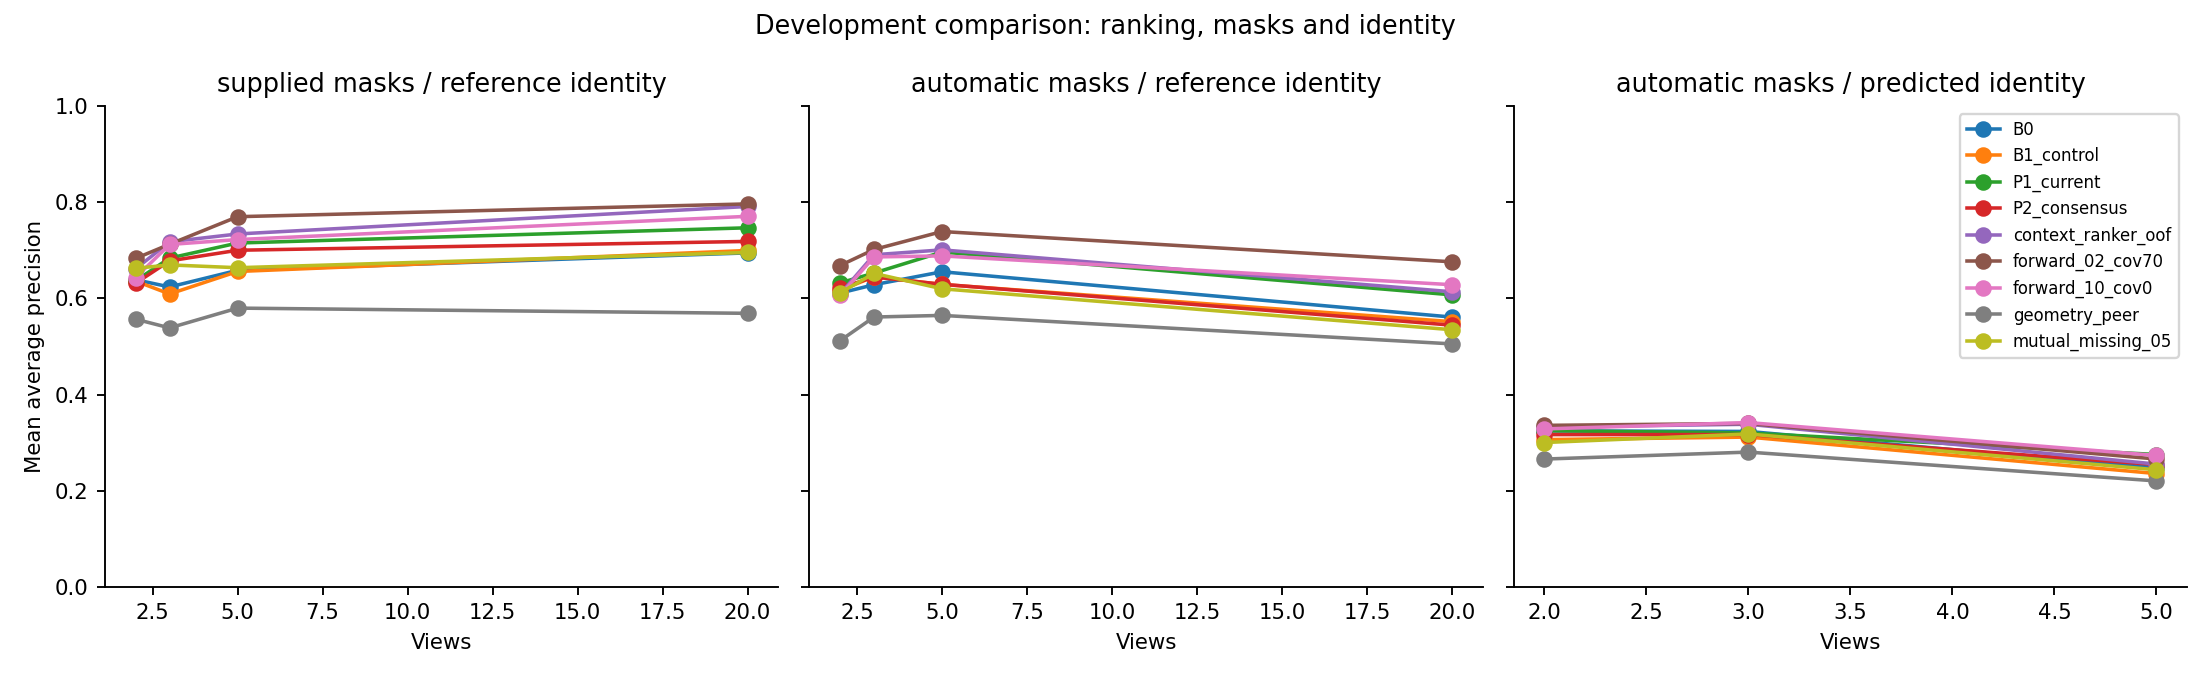

In [8]:
from IPython.display import Image, display
display(Image(filename=str(OUTPUT / 'shareable/ranking_by_route_and_views.png')))

## Object masks and odd-one-out examples

        The private gallery contains up to 24 scenes: a fixed hash-selected sample, large improvements, large regressions and deterministic coverage fill. Each panel shows three views, mask-derived boxes, SAM foreground, objects on black, coarse patch evidence and the fused selected object.

        Red is the selected track; green is the reference unusual object; blue shows all automatic object boxes. Green boxes come from supplied reference masks, so missed automatic detections remain visible. Some views may have no red box when the chosen track is unsupported. The gallery manifest records exactly how every example was selected.

In [9]:
gallery = json.loads((OUTPUT / 'private/gallery_manifest.json').read_text())
for item in gallery:
    print(item['file'], ':', item['selection_reason'])
    display(Image(filename=str(OUTPUT / 'private/figures' / item['file'])))

example_01.png : fixed hash sample


<IPython.core.display.Image object>

example_02.png : fixed hash sample


<IPython.core.display.Image object>

example_03.png : fixed hash sample


...

<IPython.core.display.Image object>

example_23.png : largest development AP increase


<IPython.core.display.Image object>

example_24.png : largest development AP increase


<IPython.core.display.Image object>

## Evidence integrity and decision boundary

Inspect both successful and unsuccessful predictions before deciding whether the directed scorer improves the project. A better supplied-mask result alone is not enough to replace the deployed scoring rule. Retain the current method unless the automatic-route comparison supports a reviewed change.

In [10]:
run_bounded([str(PYTHON), str(RUNNER), 'verify', '--model-input', str(MODEL_INPUT), '--output', str(OUTPUT)], OUTPUT.parent / 'evaluation-validation.log', idle_seconds=300, total_seconds=600)
display(json.loads((OUTPUT / 'shareable/evaluation_receipt.json').read_text()))

{'files': {'context-folds/automatic-fold-00.json': '492bb78f8ffbb72f8daf4471538880ee8d9fa3da37431eb0f32a0bb796ec7814', 'context-folds/automatic-fold-01.json': '30a7b6c0c12f15dc09aa92a5aa605f483c0f69116053bef23de519f7b6d2f602', 'context-folds/automatic-fold-02.json': '9ce133ef2b4046460ef9ec9d76e491f8686506776cbe9381bf7309da69e1649a', 'context-folds/automatic-fold-03.json': '971914ae39ba538bd693adbb150e2d8fca91cd737f85c5465e71fc883dc35b24', 'context-folds/automatic-fold-04.json': 'bc5f4c49bbd08cdeefa64d421d4131ae15c015d08c813045b24db768bdaeb0b1', 'context-folds/supplied-fold-00.json': 'd332e9ded7a498f48953ccd41c335733f6e8fdcf8ccd7d59366795b4eed0e383', 'context-folds/supplied-fold-01.json': 'aca82b785bb3fec18c95e3399e3c3a189e352f48bddefcefadccb75616996d91', 'context-folds/supplied-fold-02.json': '110f0878996e4247aac300c2b7d89a10629aca2e372f34ace90d5f386dda6728', 'context-folds/supplied-fold-03.json': 'e3cfedf8533a4bbf33aeaa0656cfac95139bf65bdb9f8c0bbbe6c4df4eab4946', 'context-folds/suppli

{'evaluator_lock_sha256': '8012cd20c63b3788f861f2ba991b3181a0c1666f26e176beeee370228c8500c3',
 'excluded_failed_scenes': 0,
 'methods': ['B0',
  'B1_control',
  'P1_current',
  'forward_10_cov0',
  'forward_02_cov70',
  'mutual_missing_05',
  'geometry_peer',
  'P2_consensus',
  'context_ranker_oof'],
 'prediction_lock_sha256': '12ce9bfc2bb401c29621d91000c53ff4fd39504fc28e55ff8a921e0b5443690d',
 'primary_comparison': 'automatic masks, predicted identity, 3 views',
 'producer': 'dinov2-small',
 'promotion': 'review required; no automatic promotion',
 'scene_count': 100,
 'scope': 'development only with asset-grouped out-of-fold context scores',
 'warning': 'No result is untouched confirmation. Reference identity and supplied masks are diagnostic routes.'}

## Experiment tracking

        Scientific outputs are already saved. ClearML receives aggregate tables, charts, metrics and hash receipts, not labels, raw images, full feature caches or local source files. Tracking has a separate timeout and can be retried without inference. A completed SDK upload still requires remote artifact verification before a run receives the final tag.

In [11]:
from scoring_comparison_runtime import tracking_credentials
if tracking_credentials():
    try:
        subprocess.run([
            str(PYTHON), '-m', 'pip', 'install', '--retries', '1', '--timeout', '30',
            '--only-binary=:all:', '--upgrade', '--target', str(PACKAGE_ROOT),
            '-r', str(SOURCE / 'requirements/scoring-comparison-tracking.txt'),
        ], check=True, timeout=180)
        subprocess.run([str(PYTHON), str(SOURCE / 'scripts/log_scoring_comparison.py'), '--evidence', str(OUTPUT), '--notebook', '08H'], check=True, timeout=180)
    except (subprocess.CalledProcessError, subprocess.TimeoutExpired):
        print('ClearML upload is not verified. Preserve the outputs and retry tracking separately.')
else:
    print('ClearML secrets are unavailable. Preserve the outputs and enable the existing notebook secrets.')

ClearML secrets are unavailable. Preserve the outputs and enable the existing notebook secrets.


## Evidence export

        Download the executed notebook, logs and complete output directory. Verify checksums after download. Keep private images, labels, per-scene evaluation rows and feature caches outside the GitHub-ready folder. Only reviewed, sanitized evidence belongs in a later repository package.

        Do not call a model final because a notebook completed. Read the paired development comparison, failure examples, tie sensitivity and identity support first. Protected evaluation remains paused until both team members reconcile which object assets have already been used.

In [12]:
print('Saved evidence:', OUTPUT)
print('Download the complete output directory and verify its lock file.')

Saved evidence: /kaggle/working/scoring-comparison-08h
Download the complete output directory and verify its lock file.


## Working-directory cleanup

        Remove only disposable dependency, extraction and plotting directories after the scientific output and optional tracking attempt are complete. Prediction checkpoints, evidence, logs and lock files remain in the stage output. This keeps Kaggle downloads compact and does not affect recovery.

In [13]:
disposable_paths = [
    PACKAGE_ROOT,
    Path('/kaggle/working/matplotlib'),
    Path('/kaggle/working/scoring-source'),
    Path('/kaggle/working/scoring-model-resource'),
    Path('/kaggle/working/scoring-evaluator-resource'),
]
for disposable_path in disposable_paths:
    if disposable_path.exists():
        shutil.rmtree(disposable_path)
print('Disposable Kaggle working directories removed. Scientific evidence is unchanged.')

Disposable Kaggle working directories removed. Scientific evidence is unchanged.
